<a href="https://colab.research.google.com/github/Jahura7/Mammographic_Mass_Classification_with_a_Decision_Tree/blob/experiment.ipynb/Mammographic_Mass_Classification_with_a_Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1. Import Libraries and Set Reproducibility**

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)

In [4]:
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_validate,
)

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42
TEST_SIZE = 0.20

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# **2. Load and Validate the data**

In [6]:
df = pd.read_csv("mammographic_masses_data_clean.csv")

In [7]:
df.head()

,BI-RADS,Age,Shape,Margin,Density,Target
0,5,67,3,5,3,1
1,5,58,4,5,3,1
2,4,28,1,1,3,0
3,5,57,1,5,3,1
4,5,76,1,4,3,1


In [8]:
df.tail()

,BI-RADS,Age,Shape,Margin,Density,Target
825,4,47,2,1,3,0
826,4,56,4,5,3,1
827,4,64,4,5,3,0
828,5,66,4,5,3,1
829,4,62,3,3,3,0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 830 entries, 0 to 829
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   BI-RADS  830 non-null    int64
 1   Age      830 non-null    int64
 2   Shape    830 non-null    int64
 3   Margin   830 non-null    int64
 4   Density  830 non-null    int64
 5   Target   830 non-null    int64
dtypes: int64(6)
memory usage: 39.0 KB


In [10]:
df.shape

(830, 6)

In [11]:
df.dtypes

,0
BI-RADS,int64
Age,int64
Shape,int64
Margin,int64
Density,int64
Target,int64


In [12]:
df.isna().sum().to_frame("missing_values")

,missing_values
BI-RADS,0
Age,0
Shape,0
Margin,0
Density,0
Target,0


In [13]:
df.duplicated().sum()

np.int64(266)

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
BI-RADS,830.0,4.393976,1.888371,0.0,4.0,4.0,5.0,55.0
Age,830.0,55.781928,14.671782,18.0,46.0,57.0,66.0,96.0
Shape,830.0,2.781928,1.242361,1.0,2.0,3.0,4.0,4.0
Margin,830.0,2.813253,1.567175,1.0,1.0,3.0,4.0,5.0
Density,830.0,2.915663,0.350936,1.0,3.0,3.0,3.0,4.0
Target,830.0,0.485542,0.500092,0.0,0.0,0.0,1.0,1.0


In [15]:
df["Target"].value_counts(dropna=False).sort_index().to_frame("count")

,count
Target,
0,427
1,403


**Data Validation before trainning**

In [16]:
# step1 : Define the feature columns and Target columns

feature_columns = ["BI-RADS", "Age", "Shape", "Margin", "Density"]
target_column = "Target"

In [17]:
# Step 2: Convert columns to numeric values

for column in feature_columns + [target_column]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

In [18]:
# Step 3: Check for missing target values

if df[target_column].isna().any():
    raise ValueError(
        "Target contains missing or non-numeric values; investigate before modelling."
    )

In [19]:
# Step 4: Check that the target is binary

target_values = set(df[target_column].unique())

In [20]:
# Step 5: Verify target contains exactly 0 and 1

if not target_values.issubset({0, 1}) or len(target_values) != 2:
    raise ValueError(
        f"Expected a binary target coded 0/1; found {sorted(target_values)}."
    )

**Define X and y**

In [21]:
X = df[feature_columns]
y = df[target_column].astype(int)

print("Features:", feature_columns)
print("Target labels:", sorted(y.unique()))
print("Target proportions:")
display(y.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Features: ['BI-RADS', 'Age', 'Shape', 'Margin', 'Density']
Target labels: [np.int64(0), np.int64(1)]
Target proportions:


,proportion
Target,
0,0.514458
1,0.485542


# **3. Explore the Data**

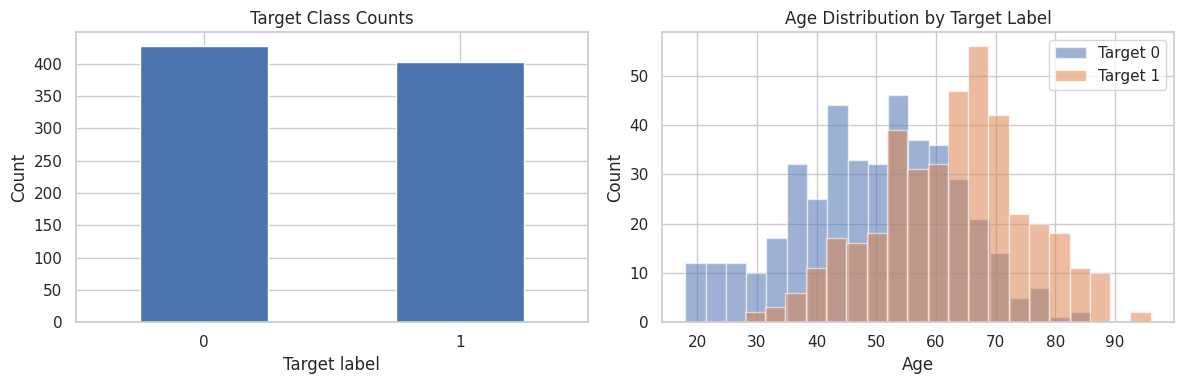

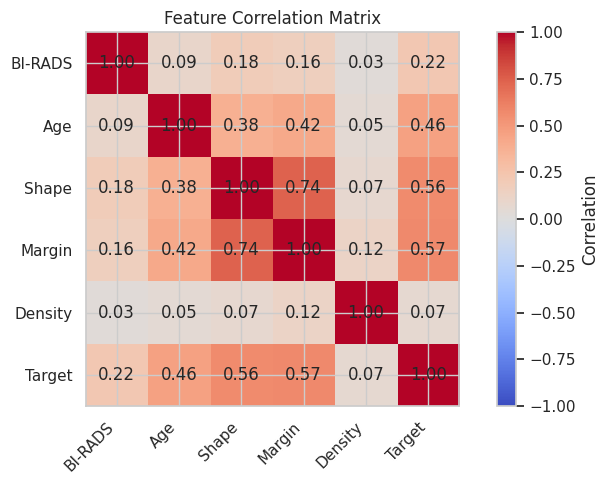

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["Target"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Target Class Counts")
axes[0].set_xlabel("Target label")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=0)

for label in sorted(df["Target"].unique()):
    axes[1].hist(df.loc[df["Target"] == label, "Age"], bins=20, alpha=0.55, label=f"Target {label}")
axes[1].set_title("Age Distribution by Target Label")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Count")
axes[1].legend()

plt.tight_layout()
plt.show()

corr = df[feature_columns + [target_column]].corr()
fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), labels=corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)), labels=corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="Correlation")
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

**EDA Findings:**

* The dataset contains 830 records and six columns.



* The target classes are reasonably balanced: 427 records in class 0 and 403 in class 1.



* Class 1 has a higher mean age than class 0.



* Shape and Margin: These features are strongly associated with each other, meaning their encoded values tend to vary together.



* Margin and Shape with Target: Both show stronger correlations with the target than Density does.



* Age: Shows a moderate positive association with the target codes.



* Density: Has very little linear correlation with the target codes in this dataset.

# **4. Create a stratified train/test split**

The test set is held out until the final evaluation. Stratification helps preserve the target-class proportions in both sets. All model selection and cross-validation happen using the training set only.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Test set:     {X_test.shape[0]} rows")

Training set: 664 rows
Test set:     166 rows


In [24]:
split_summary = pd.DataFrame({
    "Full dataset": y.value_counts(normalize=True).sort_index(),
    "Training set": y_train.value_counts(normalize=True).sort_index(),
    "Test set": y_test.value_counts(normalize=True).sort_index(),
}).rename_axis("Target label")
display(split_summary)

,Full dataset,Training set,Test set
Target label,,,
0,0.514458,0.51506,0.512048
1,0.485542,0.48494,0.487952


# **5. Establish a simple baseline**

A dummy classifier provides a reference point. A useful model should outperform this baseline on relevant metrics, not just report a seemingly high accuracy.

In [25]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

baseline_results = {
    "Model": "Most-frequent baseline",
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, baseline_pred),
    "Precision (label 1)": precision_score(y_test, baseline_pred, pos_label=1, zero_division=0),
    "Recall (label 1)": recall_score(y_test, baseline_pred, pos_label=1, zero_division=0),
    "F1 (label 1)": f1_score(y_test, baseline_pred, pos_label=1, zero_division=0),
}
display(pd.DataFrame([baseline_results]).set_index("Model"))

,Accuracy,Balanced accuracy,Precision (label 1),Recall (label 1),F1 (label 1)
Model,,,,,
Most-frequent baseline,0.512048,0.5,0.0,0.0,0.0


# **6. Build a preprocessing and modelling pipeline**

The median imputer is placed inside the pipeline so it is fitted only on the relevant training fold during cross-validation. The current CSV has no missing values, but this makes the workflow more robust if missing values appear later. Decision trees do not require feature scaling, so scaling is not included.

In [26]:
tree_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

param_grid = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [None, 3, 5, 8],
    "classifier__min_samples_split": [2, 10],
    "classifier__min_samples_leaf": [1, 4],
    "classifier__class_weight": [None, "balanced"],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    error_score="raise",
)

grid_search.fit(X_train, y_train)

print("Best cross-validation F1 (label 1):", round(grid_search.best_score_, 4))
print("Best parameters:")
display(pd.Series(grid_search.best_params_, name="value").to_frame())

Best cross-validation F1 (label 1): 0.8185
Best parameters:


,value
classifier__class_weight,balanced
classifier__criterion,entropy
classifier__max_depth,3
classifier__min_samples_leaf,1
classifier__min_samples_split,2


# **7. Cross-validation summary for the selected model**

The grid search selects parameters using training data only.  

In [27]:
best_model = grid_search.best_estimator_

cv_scores = cross_validate(
    best_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc",
    },
    n_jobs=-1,
)

cv_summary = pd.DataFrame({
    metric.replace("test_", ""): [
        np.mean(cv_scores[metric]),
        np.std(cv_scores[metric], ddof=1),
    ]
    for metric in cv_scores if metric.startswith("test_")
}, index=["Mean", "Std. deviation"]).T

display(cv_summary.round(4))

,Mean,Std. deviation
accuracy,0.8299,0.0613
balanced_accuracy,0.8285,0.0607
precision,0.8547,0.0785
recall,0.7859,0.0497
f1,0.8185,0.0612
roc_auc,0.8872,0.0474


# **8. Final evaluation on the  test set**

In [30]:
y_pred = best_model.predict(X_test)

test_results = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision (label 1)": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
    "Recall (label 1)": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
    "F1 (label 1)": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
}]).T.rename(columns={0: "Test score"})

if hasattr(best_model, "predict_proba"):
    y_prob = best_model.predict_proba(X_test)[:, list(best_model.named_steps["classifier"].classes_).index(1)]
    test_results.loc["ROC-AUC"] = roc_auc_score(y_test, y_prob)

display(test_results.round(4))



,Test score
Accuracy,0.8554
Balanced accuracy,0.8542
Precision (label 1),0.8904
Recall (label 1),0.8025
F1 (label 1),0.8442
ROC-AUC,0.8726


In [29]:

print("Classification report (labels shown as 0 and 1):")
print(classification_report(y_test, y_pred, labels=[0, 1], zero_division=0))

Classification report (labels shown as 0 and 1):
              precision    recall  f1-score   support

           0       0.83      0.91      0.87        85
           1       0.89      0.80      0.84        81

    accuracy                           0.86       166
   macro avg       0.86      0.85      0.85       166
weighted avg       0.86      0.86      0.85       166



**Vizualization of Test Confusion Matrix and Test ROC Curve**

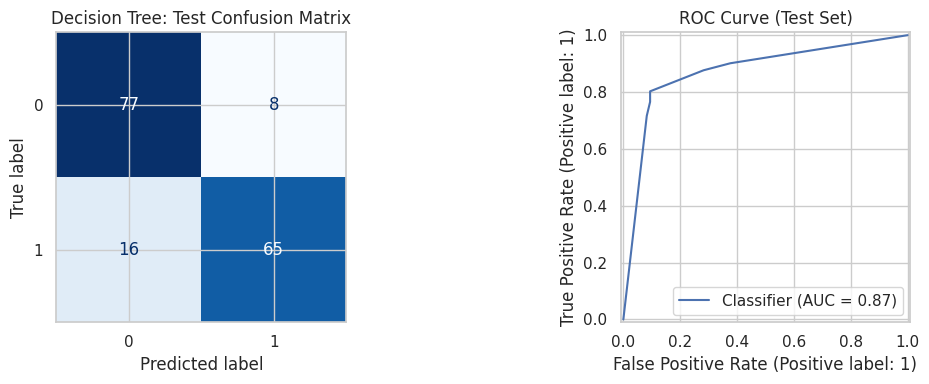

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1], cmap="Blues", colorbar=False, ax=axes[0]
)
axes[0].set_title("Decision Tree: Test Confusion Matrix")

if hasattr(best_model, "predict_proba"):
    RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1])
    axes[1].set_title("ROC Curve (Test Set)")
else:
    axes[1].axis("off")
    axes[1].text(0.5, 0.5, "Probability estimates unavailable", ha="center", va="center")

plt.tight_layout()
plt.show()

# **9. Inspect feature importance**

,importance
BI-RADS,0.717299
Shape,0.175917
Age,0.078513
Margin,0.014328
Density,0.013943


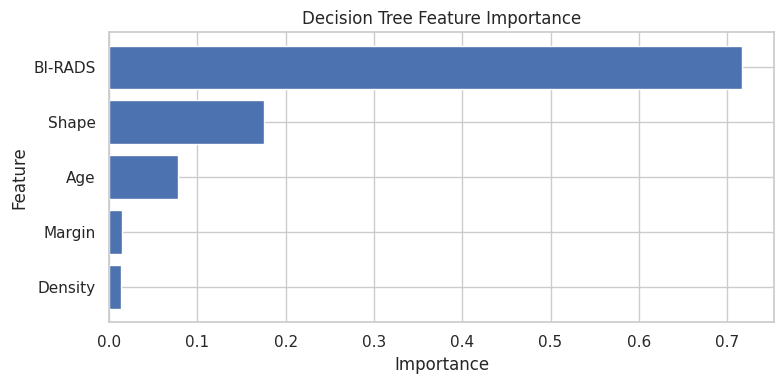

In [32]:
fitted_tree = best_model.named_steps["classifier"]
importance = pd.Series(
    fitted_tree.feature_importances_,
    index=feature_columns,
    name="importance",
).sort_values(ascending=False)

display(importance.to_frame())

plt.figure(figsize=(8, 4))
plt.barh(importance.index[::-1], importance.values[::-1])
plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# **10. Visualize the selected decision tree**

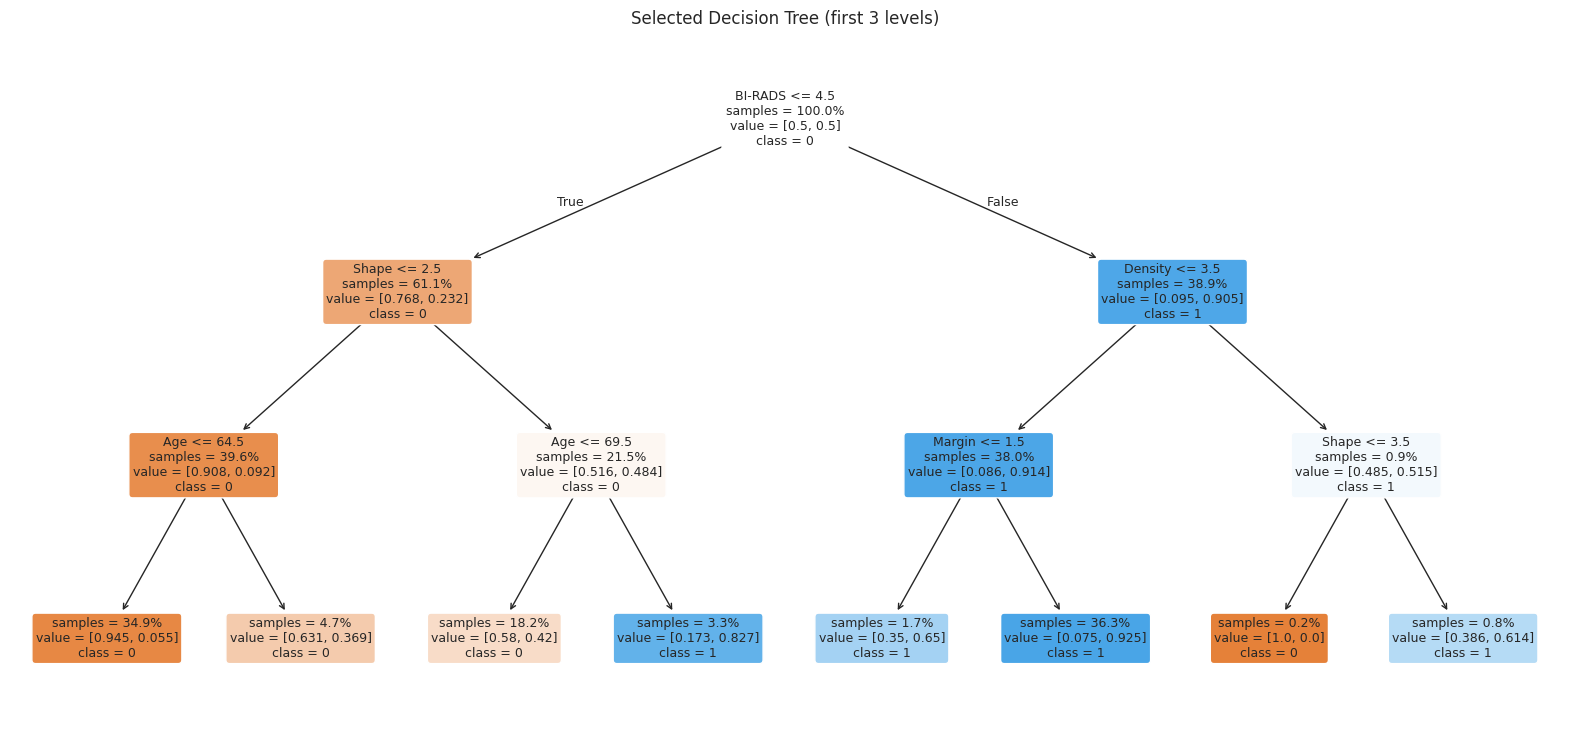

In [33]:
plt.figure(figsize=(20, 9))
plot_tree(
    fitted_tree,
    feature_names=feature_columns,
    class_names=[str(label) for label in fitted_tree.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    proportion=True,
    impurity=False,
    fontsize=9,
)
plt.title("Selected Decision Tree (first 3 levels)")
plt.show()

# **11. Compare the tuned model with the baseline**

In [34]:
model_pred = best_model.predict(X_test)

comparison = pd.DataFrame([
    {
        "Model": "Most-frequent baseline",
        "Accuracy": accuracy_score(y_test, baseline_pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, baseline_pred),
        "F1 (label 1)": f1_score(y_test, baseline_pred, pos_label=1, zero_division=0),
    },
    {
        "Model": "Tuned Decision Tree",
        "Accuracy": accuracy_score(y_test, model_pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, model_pred),
        "F1 (label 1)": f1_score(y_test, model_pred, pos_label=1, zero_division=0),
    },
]).set_index("Model")

display(comparison.round(4))

,Accuracy,Balanced accuracy,F1 (label 1)
Model,,,
Most-frequent baseline,0.5120,0.5000,0.0000
Tuned Decision Tree,0.8554,0.8542,0.8442


# **Limitations**

- This dataset is relatively small and may not represent all patient populations or clinical settings.
- The dataset's label definitions and coding should be confirmed from its original documentation.
- A random holdout split does not establish performance across hospitals, time periods, or populations.
- Feature importance and tree rules do not establish causation.
- This model is for learning and portfolio demonstration only, not diagnosis or clinical decision support.


# **Possible next steps**

1. Compare with Logistic Regression and Random Forest using the same split and cross-validation strategy.
2. Add repeated cross-validation or nested cross-validation for a more robust estimate of model-selection performance.
3. Assess calibration and class-specific error costs.

# **Conclusion**

This project used a Decision Tree classifier to predict the target class of mammographic masses based on features such as age, BI-RADS assessment, shape, margin, and density. The dataset was explored and preprocessed, missing values were handled using a pipeline, and hyperparameter tuning was performed using cross-validation. Model performance was evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix, with a Dummy Classifier serving as a baseline. These evaluation metrics help assess how well the model distinguishes between the two target classes. However, the final conclusions should be based on the actual test results, and further validation on independent data is needed before considering any real-world medical application.